# Ways to handle missing values.

1) **Remove rows**: Remove rows having missing values.
2) **Fill missing values**: Fill missing values. There're some ways to fill missing values which are as stated below.

a) **Univariate**: Handle each column seperately. Use class `SimpleImputer` given in scikitlearn.
1) `Numeric`: Fill with mean, median, random number or EndOfDistribution(Will learn in next session.)
2) `Categorical column`: Fill with mode or use word missing.


b) **Multivariate imputation**:
Fill with class `KNNImputer` or `IterativeImputer` of sklearn.

`Session wise topics for some days from now.`

35) Remove values
36) SimpleImputer()
37) KNNImputer()
38) IterativeImputer()
39) MissingIndicator()

`Note`: ***In this session, we'll learn how to remove rows having missing values.***<br>
***Whenever we remove rows having missing values, that approach is called `Complete Case Analysis(CCA)`***


# When to perform CCA?

1) If data are `MCAR(Missing Completely at Random)`. Means it should not be like first 20 rows are having missing values, last 50 rows are having missing values or 500 middle rows are having missing values.

2) Missing data are less than 5% of the total data.
3) Distribution of data before and after removing rows, should not change.

# Note: From `day 35` to `day 38` everything is under **Univariate imputation**. From day 38, we'll start **Multivariate imputation**.



In [1]:
import pandas as pd
import numpy as np

In [2]:
df = pd.read_csv('00 ds_jobs.csv')

In [3]:
df.head()

,enrollee_id,city,city_development_index,gender,relevent_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,training_hours,target
0,8949,city_103,0.920,Male,Has relevent experience,no_enrollment,Graduate,STEM,20.0,NaN,NaN,36.0,1.0
1,29725,city_40,0.776,Male,No relevent experience,no_enrollment,Graduate,STEM,15.0,50-99,Pvt Ltd,47.0,0.0
2,11561,city_21,0.624,NaN,No relevent experience,Full time course,Graduate,STEM,5.0,NaN,NaN,83.0,0.0
3,33241,city_115,0.789,NaN,No relevent experience,NaN,Graduate,Business Degree,0.0,NaN,Pvt Ltd,52.0,1.0
4,666,city_162,0.767,Male,Has relevent experience,no_enrollment,Masters,STEM,20.0,50-99,Funded Startup,8.0,0.0


In [4]:
print(df.shape)
print(df.shape[0])    # 19158
print(df.shape[1])    # 13

(19158, 13)
19158
13


In [5]:
# Find total missing values in each columns

df.isnull().sum()

enrollee_id                  0
city                         0
city_development_index     479
gender                    4508
relevent_experience          0
enrolled_university        386
education_level            460
major_discipline          2813
experience                  65
company_size              5938
company_type              6140
training_hours             766
target                       0
dtype: int64

In [6]:
# Percentage of data missing in each column.
(df.isnull().sum()*100) / df.shape[0]    

# df.shape[0] gives total no.of rows and df.shape[1] gives total no.of columns.

enrollee_id                0.000000
city                       0.000000
city_development_index     2.500261
gender                    23.530640
relevent_experience        0.000000
enrolled_university        2.014824
education_level            2.401086
major_discipline          14.683161
experience                 0.339284
company_size              30.994885
company_type              32.049274
training_hours             3.998330
target                     0.000000
dtype: float64

# Finding columns havinf less than 5% missing values.

In [7]:
# Columns having less than 5% missing values.

columns = []

for column in df.columns:
    if (df[column].isnull().sum()*100) / df.shape[0] < 5 and (df[column].isnull().sum()*100) / df.shape[0] > 0:
        columns.append(column)

In [8]:
columns

['city_development_index',
 'enrolled_university',
 'education_level',
 'experience',
 'training_hours']

In [9]:
# 2nd way to find columns havinf less than 5% od missing data.

columns2 = []

for column in df.columns:
    missing_percentage = (df[column].isnull().sum()*100) / df.shape[0]

    if 0 < missing_percentage < 5:
        columns2.append(column)

In [10]:
columns2

['city_development_index',
 'enrolled_university',
 'education_level',
 'experience',
 'training_hours']

In [11]:
# 3rd way

columns3 = [column for column in df.columns if df[column].isnull().mean() < 0.05 and df[column].isnull().mean() > 0]

columns3

['city_development_index',
 'enrolled_university',
 'education_level',
 'experience',
 'training_hours']

# Continuation with the code.

In [12]:
df[columns].sample(10)

,city_development_index,enrolled_university,education_level,experience,training_hours
14542,0.624,no_enrollment,Masters,19.0,11.0
10144,0.939,no_enrollment,Graduate,13.0,54.0
8222,0.624,no_enrollment,Graduate,5.0,26.0
8196,0.920,no_enrollment,Graduate,17.0,34.0
5646,0.682,Full time course,Graduate,0.0,21.0
6825,0.550,no_enrollment,Graduate,9.0,77.0
4284,0.698,no_enrollment,NaN,8.0,15.0
201,0.624,no_enrollment,Graduate,2.0,39.0
1213,0.624,no_enrollment,Graduate,3.0,NaN
14753,0.910,no_enrollment,Masters,15.0,55.0


In [13]:
# See how many rows will remain after dropping.

len(df[columns].dropna())

17182

In [14]:
# See how much percentage of data will remain afteer dropping.

(len(df[columns].dropna())*100) / len(df)

89.68577095730244

In [15]:
# Removing rows having missing values.

new_df = df[columns].dropna()

In [16]:
df.shape, new_df.shape

((19158, 13), (17182, 5))

# By plotting histogram and PDF the data. check after removing rows with missing values whethere there is any change in the distribution of the data or not

In [17]:
from matplotlib import pyplot as plt
import seaborn as sns

C:\Users\jugal\AppData\Local\Temp\ipykernel_7824\221043484.py:4: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df['city_development_index'], hist = False)


Text(0.5, 1.0, 'KD plot after CCA')

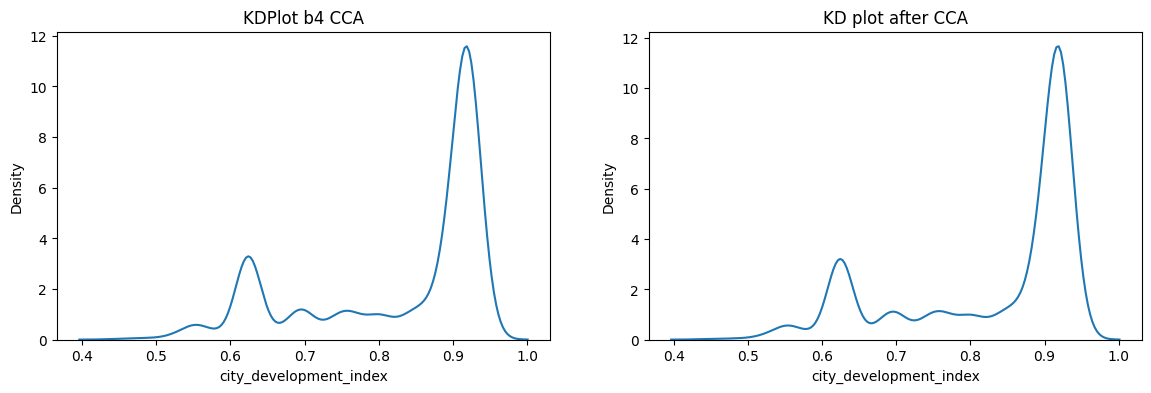

In [18]:
plt.figure(figsize = (14, 4))

plt.subplot(121)
sns.distplot(df['city_development_index'], hist = False)
plt.title('KDPlot b4 CCA')

plt.subplot(122)
sns.kdeplot(new_df['city_development_index'])
plt.title("KD plot after CCA")

# We can see the KD plot is same b4 and after applying CCA. In order to get this more clear, let's plot both these kd Plot in the same chart.

(array([  48.,  105.,  473., 2412.,  914.,  396.,  865.,  880., 2144.,
        8945.]),
 array([0.448 , 0.4981, 0.5482, 0.5983, 0.6484, 0.6985, 0.7486, 0.7987,
        0.8488, 0.8989, 0.949 ]),
 <BarContainer object of 10 artists>)

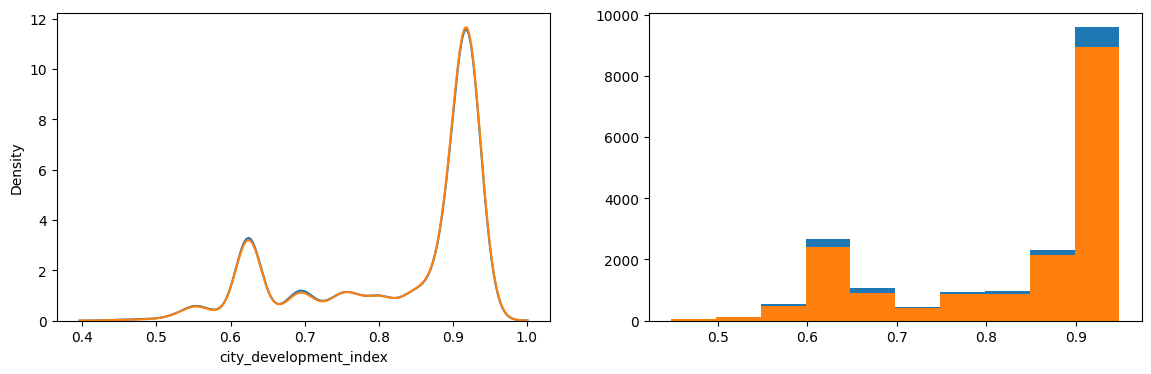

In [19]:
plt.figure(figsize = (14, 4))

plt.subplot(121)
sns.kdeplot(df['city_development_index'])
sns.kdeplot(new_df['city_development_index'])

plt.subplot(122)
plt.hist(df['city_development_index'])
plt.hist(new_df['city_development_index'])


# We can see, both KDE plot and histogram are overlaping. So it means the rows droppend were at random indices.

<AxesSubplot: >

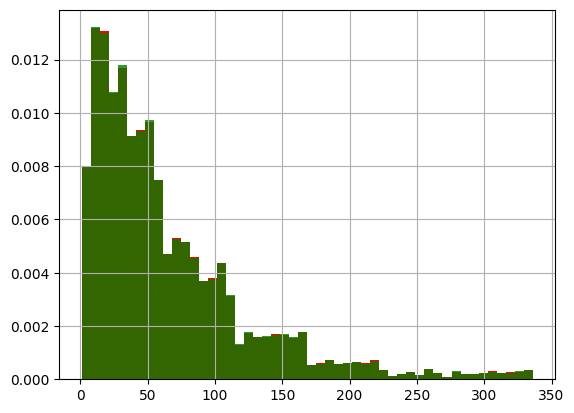

In [20]:
# Let see training hours.

df['training_hours'].hist(bins=50,  density=True, color='red')
new_df['training_hours'].hist(bins=50, color='green', density=True, alpha=0.8)

# We can see the same thing. Both the histogra before and after are overlaping.

# Let's see what is the leftover percentage of data after CCA

In [21]:
print(df['enrolled_university'].value_counts() / len(df))

print()
print()
print()

print(new_df['enrolled_university'].value_counts() / len(new_df))

no_enrollment       0.721213
Full time course    0.196106
Part time course    0.062533
Name: enrolled_university, dtype: float64



no_enrollment       0.735188
Full time course    0.200733
Part time course    0.064079
Name: enrolled_university, dtype: float64


In [22]:
print(df['education_level'].value_counts() / len(df) * 100)

print()
print()
print()

print(new_df['education_level'].value_counts() / len(new_df) * 100)

Graduate          60.538678
Masters           22.763336
High School       10.528239
Phd                2.160977
Primary School     1.607683
Name: education_level, dtype: float64



Graduate          61.983471
Masters           23.408218
High School       10.737982
Phd                2.211617
Primary School     1.658713
Name: education_level, dtype: float64


In [23]:
# Let's create dataframe of these data.

data = [df.enrolled_university.value_counts() / len(df),
       new_df.enrolled_university.value_counts() / len(new_df)]
print(data)

print()
print()
print()

print(data[0])

[no_enrollment       0.721213
Full time course    0.196106
Part time course    0.062533
Name: enrolled_university, dtype: float64, no_enrollment       0.735188
Full time course    0.200733
Part time course    0.064079
Name: enrolled_university, dtype: float64]



no_enrollment       0.721213
Full time course    0.196106
Part time course    0.062533
Name: enrolled_university, dtype: float64


In [24]:
# Concating

enroll_uni = pd.concat(data, axis = 'columns')
enroll_uni.columns = ['Before CCA', 'After CCA']

enroll_uni

,Before CCA,After CCA
no_enrollment,0.721213,0.735188
Full time course,0.196106,0.200733
Part time course,0.062533,0.064079


In [25]:
# Education_level.

data = [df.education_level.value_counts() / len(df),
       new_df.education_level.value_counts() / len(new_df)]

In [26]:
# Concat

edu_level = pd.concat(data, axis = 'columns')
edu_level.columns = ['Before CCA', 'After CCA']

edu_level

,Before CCA,After CCA
Graduate,0.605387,0.619835
Masters,0.227633,0.234082
High School,0.105282,0.107380
Phd,0.021610,0.022116
Primary School,0.016077,0.016587
